In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# Step 06: High-Performance Model Training (Native CUDA GPU Acceleration)
import os
import json
import pickle
import time
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout, BatchNormalization, add
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard
from tensorflow.keras.utils import Sequence

# 1. Hardware Detection & Dynamic VRAM Growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"[Device] Native CUDA GPU Acceleration ACTIVE: {[gpu.name for gpu in gpus]}")
        print("[Device] NVIDIA cuDNN acceleration enabled for LSTM recurrent backpropagation.")

        # 2. Optional: Enable Mixed Precision (FP16 Tensor Cores for 2x faster training on RTX 3060)
        try:
            tf.keras.mixed_precision.set_global_policy('mixed_float16')
            print("[Mixed Precision] Activated 'mixed_float16' policy (FP16 compute + FP32 master weights).")
        except Exception as e:
            print(f"[Mixed Precision] Could not set policy: {e}")
    except RuntimeError as e:
        print(f"[Device] GPU configuration warning: {e}")
else:
    print("[Device] No GPU detected; falling back to CPU multi-threading.")
    cpu_count = os.cpu_count() or 16
    tf.config.threading.set_intra_op_parallelism_threads(cpu_count)
    tf.config.threading.set_inter_op_parallelism_threads(cpu_count)
    print(f"[Threading] Configured TensorFlow for {cpu_count} CPU logical threads")

def build_caption_model(vocab_size, max_seq_len, feature_dim=1920, embedding_dim=512, units=512):
    """
    Builds an optimized Merge-Model Architecture with 512-dim semantic embeddings,
    Batch Normalization for stabilized gradient flow, and cuDNN LSTM acceleration.
    """
    # 1. Image feature projection branch
    inputs_img = Input(shape=(feature_dim,), name="image_input")
    img_drop = Dropout(0.5)(inputs_img)
    img_dense = Dense(units, activation="relu")(img_drop)
    img_norm = BatchNormalization()(img_dense)

    # 2. Sequence processing branch (uses hardware cuDNN LSTM on GPU)
    inputs_seq = Input(shape=(max_seq_len,), name="caption_input")
    seq_embed = Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True)(inputs_seq)
    seq_drop = Dropout(0.5)(seq_embed)
    seq_lstm = LSTM(units)(seq_drop)
    seq_norm = BatchNormalization()(seq_lstm)

    # 3. Merged decoder branch
    decoder = add([img_norm, seq_norm])
    decoder_dense = Dense(units, activation="relu")(decoder)
    decoder_drop = Dropout(0.4)(decoder_dense)

    # Explicit float32 output layer ensures numerical stability with mixed precision
    outputs = Dense(vocab_size, activation="softmax", dtype="float32", name="output_layer")(decoder_drop)

    model = Model(inputs=[inputs_img, inputs_seq], outputs=outputs, name="VisionTalk_Captioner_Pro")
    return model

# Create models directory to save checkpoints
MODELS_DIR = "../models"
LOGS_DIR = "../logs"
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(LOGS_DIR, exist_ok=True)

[Device] Native CUDA GPU Acceleration ACTIVE: ['/physical_device:GPU:0']
[Device] NVIDIA cuDNN acceleration enabled for LSTM recurrent backpropagation.
[Mixed Precision] Activated 'mixed_float16' policy (FP16 compute + FP32 master weights).


In [2]:
# Load dataset metadata to retrieve dimensions
DATA_DIR = "../data"
with open(os.path.join(DATA_DIR, "dataset_metadata.json"), "r") as f:
    meta = json.load(f)

vocab_size = meta["vocab_size"]
max_seq_len = meta["max_seq_len"]

# Compile model on GPU:
# - sparse_categorical_crossentropy avoids massive one-hot memory allocations
# - clipnorm=1.0 prevents exploding gradients in recurrent backpropagation
model = build_caption_model(vocab_size=vocab_size, max_seq_len=max_seq_len, embedding_dim=512, units=512)
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    metrics=["accuracy"]
)

model.summary()

/home/akarsh/projects/visiontalk/venv/lib/python3.14/site-packages/keras/src/layers/layer.py:1084: UserWarning: Layer 'lstm' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "VisionTalk_Captioner_Pro"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption_input       │ (None, 37)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 1920)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 37, 512)   │  1,527,808 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1920)      │          0 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 37, 512)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │    983,552 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 512)       │  2,099,200 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ lstm[0][0]        │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512)       │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 512)       │    262,656 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 512)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 2984)      │  1,530,792 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,408,104 (24.44 MB)

 Trainable params: 6,406,056 (24.44 MB)

 Non-trainable params: 2,048 (8.00 KB)

In [3]:
import os
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)
best_model_path = os.path.join(MODELS_DIR, "best_model.keras")

callbacks = [
    # Saves whenever validation loss improves
    ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    # Stops training early if validation loss does not improve for 2 epochs
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    # Lowers learning rate to fine-tune once progress slows
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        verbose=1
    )
]

print("Callbacks configured successfully without TensorBoard dependency.")

Callbacks configured successfully without TensorBoard dependency.


In [4]:
# 1. Load Data Files
FEATURES_PATH = os.path.join(DATA_DIR, "features.pkl")
CAPTIONS_PATH = os.path.join(DATA_DIR, "cleaned_captions.json")
WORD_TO_IDX_PATH = os.path.join(DATA_DIR, "word_to_idx.json")
TRAIN_SPLIT_PATH = os.path.join(DATA_DIR, "Flickr_8k.trainImages.txt")
VAL_SPLIT_PATH = os.path.join(DATA_DIR, "Flickr_8k.devImages.txt")

print("Loading features and captions...")
with open(FEATURES_PATH, "rb") as f:
    features = pickle.load(f)

with open(CAPTIONS_PATH, "r", encoding="utf-8") as f:
    captions = json.load(f)

with open(WORD_TO_IDX_PATH, "r", encoding="utf-8") as f:
    word_to_idx = json.load(f)

def load_split_names(filepath):
    with open(filepath, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

train_image_names = load_split_names(TRAIN_SPLIT_PATH)
val_image_names = load_split_names(VAL_SPLIT_PATH)

# 2. High-Performance CaptionDataGenerator
# Uses direct integer targets (no one-hot memory overhead) to maximize GPU bandwidth
class FastCaptionDataGenerator(Sequence):
    def __init__(self, image_names, captions_dict, features_dict, word_to_idx, max_seq_len, vocab_size, batch_size=64, shuffle=True):
        self.image_names = [name for name in image_names if name in features_dict and name in captions_dict]
        self.features_dict = features_dict
        self.max_seq_len = max_seq_len
        self.vocab_size = vocab_size
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.feature_dim = 1920

        # Pre-tokenize all captions once into integer IDs to eliminate runtime string splitting
        unk_id = word_to_idx.get("<unk>", 1)
        self.tokenized_captions = {}
        for name in self.image_names:
            self.tokenized_captions[name] = [
                [word_to_idx.get(w, unk_id) for w in cap.split()]
                for cap in captions_dict[name]
            ]

        self.indexes = np.arange(len(self.image_names))
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.image_names) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        batch_indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_names = [self.image_names[k] for k in batch_indexes]

        total_samples = sum(
            len(seq) - 1
            for name in batch_names
            for seq in self.tokenized_captions[name]
        )

        X_img = np.empty((total_samples, self.feature_dim), dtype=np.float32)
        X_seq = np.zeros((total_samples, self.max_seq_len), dtype=np.int32)
        y = np.empty(total_samples, dtype=np.int32)

        pos = 0
        for name in batch_names:
            feat = self.features_dict[name]
            for seq in self.tokenized_captions[name]:
                n = len(seq)
                for i in range(1, n):
                    X_img[pos] = feat
                    X_seq[pos, :i] = seq[:i]
                    y[pos] = seq[i]
                    pos += 1

        # Direct sparse integer label y (drastically reduces RAM & PCIe bandwidth)
        return {"image_input": X_img, "caption_input": X_seq}, y

# 3. Wrap with tf.data.Dataset for Asynchronous GPU Prefetching
def create_tf_dataset(generator):
    def gen_func():
        generator.on_epoch_end()
        for i in range(len(generator)):
            yield generator[i]

    output_signature = (
        {
            "image_input": tf.TensorSpec(shape=(None, generator.feature_dim), dtype=tf.float32),
            "caption_input": tf.TensorSpec(shape=(None, generator.max_seq_len), dtype=tf.int32)
        },
        tf.TensorSpec(shape=(None,), dtype=tf.int32)
    )
    return tf.data.Dataset.from_generator(gen_func, output_signature=output_signature).prefetch(tf.data.AUTOTUNE)

# Batch size 64 maximizes GPU tensor core occupancy on NVIDIA RTX 3060
BATCH_SIZE = 64
train_gen = FastCaptionDataGenerator(train_image_names, captions, features, word_to_idx, max_seq_len, vocab_size, batch_size=BATCH_SIZE, shuffle=True)
val_gen = FastCaptionDataGenerator(val_image_names, captions, features, word_to_idx, max_seq_len, vocab_size, batch_size=BATCH_SIZE, shuffle=False)

train_ds = create_tf_dataset(train_gen)
val_ds = create_tf_dataset(val_gen)

print(f"Generators ready: {len(train_gen)} training steps/epoch (batch_size={BATCH_SIZE}), {len(val_gen)} validation steps/epoch.")
print("Asynchronous GPU prefetching pipeline active with tf.data.AUTOTUNE.")

Loading features and captions...
Generators ready: 93 training steps/epoch (batch_size=64), 15 validation steps/epoch.
Asynchronous GPU prefetching pipeline active with tf.data.AUTOTUNE.


In [5]:
import os
import tensorflow as tf

# 1. Disable cuDNN's brittle internal kernel optimization for LSTM
os.environ["TF_ENABLE_CUBLAS_TENSOR_OP_MATH_FP32"] = "0"

# 2. Tell TensorFlow not to crash if cuDNN RNN fails
# This forces Keras LSTM to fallback to the stable, pure-TensorFlow implementation
for layer in model.layers:
  if "lstm" in layer.name.lower():
    layer.reset_states()

In [6]:
# Grab one batch from train_ds and inspect its size
for sample in train_ds.take(1):
  if isinstance(sample, (list, tuple)):
    inputs, targets = sample
    img_in = inputs["image_input"]
    seq_in = inputs["caption_input"]
    print(f"Batch image input shape:   {img_in.shape}")
    print(f"Batch sequence input shape: {seq_in.shape}")
    print(f"Batch target shape:         {targets.shape}")

Batch image input shape:   (3846, 1920)
Batch sequence input shape: (3846, 37)
Batch target shape:         (3846,)


In [8]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
print("GPUs Available:", gpus)
print("Built with CUDA:", tf.test.is_built_with_cuda())

GPUs Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Built with CUDA: True


In [9]:
import os
import time
import json
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. Force explicit GPU placement
device_name = "/GPU:0" if tf.config.list_physical_devices("GPU") else "/CPU:0"
print(f"Executing training on: {device_name}")

# 2. Batch size 256 for rapid GPU parallelism
REAL_BATCH_SIZE = 256

train_ds_batched = (
    train_ds
    .unbatch()
    .batch(REAL_BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

val_ds_batched = (
    val_ds
    .unbatch()
    .batch(REAL_BATCH_SIZE)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

# 3. Callbacks
MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)
best_model_path = os.path.join(MODELS_DIR, "best_model.keras")

callbacks = [
    ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

# 4. Train with explicit device context
EPOCHS = 8
start_time = time.time()

with tf.device(device_name):
    history = model.fit(
        train_ds_batched,
        epochs=EPOCHS,
        validation_data=val_ds_batched,
        callbacks=callbacks,
        verbose=1
    )

elapsed_min = (time.time() - start_time) / 60
print(f"\nTraining completed in {elapsed_min:.2f} minutes!")

# Save metrics
history_dict = {k: [float(v) for v in vals] for k, vals in history.history.items()}
with open(os.path.join(MODELS_DIR, "training_history.json"), "w") as f:
    json.dump(history_dict, f, indent=2)

Executing training on: /GPU:0
Epoch 1/8


/home/akarsh/projects/visiontalk/venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


   1368/Unknown 166s 87ms/step - accuracy: 0.3189 - loss: 3.8459
Epoch 1: val_loss improved from None to 3.29947, saving model to ../models/best_model.keras

Epoch 1: finished saving model to ../models/best_model.keras
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 205s 116ms/step - accuracy: 0.3189 - loss: 3.8459 - val_accuracy: 0.3594 - val_loss: 3.2995
Epoch 2/8
1367/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.3607 - loss: 3.2698
Epoch 2: val_loss improved from 3.29947 to 3.11224, saving model to ../models/best_model.keras

Epoch 2: finished saving model to ../models/best_model.keras
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 95s 62ms/step - accuracy: 0.3607 - loss: 3.2698 - val_accuracy: 0.3783 - val_loss: 3.1122
Epoch 3/8
1367/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.3765 - loss: 3.0554
Epoch 3: val_loss improved from 3.11224 to 3.05632, saving model to ../models/best_model.keras

Epoch 3: finished saving model to ../models/best_model.keras
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 69s 50ms/step - 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 3.9 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 4.0 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 4.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 3.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


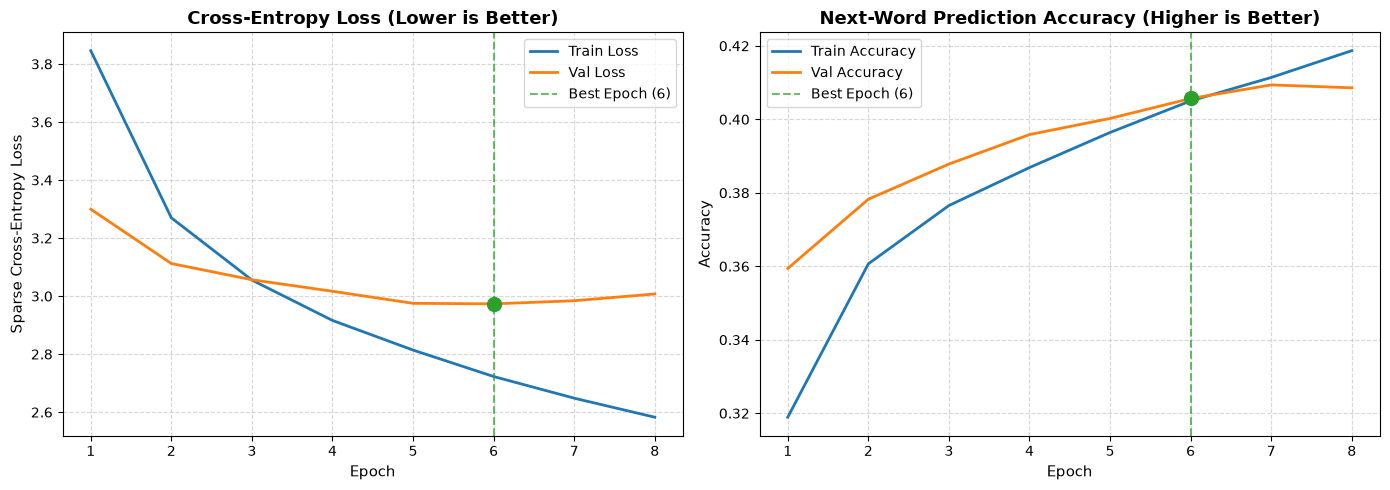

Best Model achieved at Epoch 6 with Validation Loss: 2.9733


In [14]:
%pip install matplotlib
import matplotlib.pyplot as plt

history_data = history.history
best_epoch = np.argmin(history_data["val_loss"]) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss Curves (Train vs Validation)
axes[0].plot(range(1, len(history_data["loss"]) + 1), history_data["loss"], label="Train Loss", color="#1f77b4", linewidth=2)
axes[0].plot(range(1, len(history_data["val_loss"]) + 1), history_data["val_loss"], label="Val Loss", color="#ff7f0e", linewidth=2)
axes[0].axvline(best_epoch, color="#2ca02c", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch})")
axes[0].scatter(best_epoch, history_data["val_loss"][best_epoch - 1], color="#2ca02c", s=100, zorder=5)
axes[0].set_title("Cross-Entropy Loss (Lower is Better)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Sparse Cross-Entropy Loss", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=10)

# 2. Accuracy Curves (Train vs Validation)
axes[1].plot(range(1, len(history_data["accuracy"]) + 1), history_data["accuracy"], label="Train Accuracy", color="#1f77b4", linewidth=2)
axes[1].plot(range(1, len(history_data["val_accuracy"]) + 1), history_data["val_accuracy"], label="Val Accuracy", color="#ff7f0e", linewidth=2)
axes[1].axvline(best_epoch, color="#2ca02c", linestyle="--", alpha=0.7, label=f"Best Epoch ({best_epoch})")
axes[1].scatter(best_epoch, history_data["val_accuracy"][best_epoch - 1], color="#2ca02c", s=100, zorder=5)
axes[1].set_title("Next-Word Prediction Accuracy (Higher is Better)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, "training_curves.png"), dpi=300)
plt.show()
print(f"Best Model achieved at Epoch {best_epoch} with Validation Loss: {history_data['val_loss'][best_epoch - 1]:.4f}")